In [1]:
%%time
dataset_name = "W29_comb"
df_list = "BES_Panel"

%matplotlib inline 
%run BES_header.py {dataset_name} {df_list}

global BES_label_list, BES_df_list

Toggle code

CPU times: total: 14.5 s
Wall time: 1min 1s


In [ ]:
# * W9 credit/blame Leave - interesting - looks like a lot Labour people blamed Corbyn

# breakdown vs 2015 vote?


# 1,2,3,4,5,6,7,8 , 12
# each No/Yes/Don't know

# blame for <voted remain>, credit for <voted leave>

# p_past_vote_2015, p_turnout_2015  last ge
# p_eurefvote, p_eurefturnout  - already split

# wt_new_W9

In [68]:
mask = BES_Panel["countryW9"]=="England"
GE2015 = BES_Panel["p_past_vote_2015"][mask].astype('object')
# GE2015.value_counts()
# GE2015.cat.categories
replace_dict = {'Conservative':"CON", 'Labour':"LAB", 'Liberal Democrat':"LD",
       'Scottish National Party (SNP)':np.nan, 'Plaid Cymru':np.nan,
       'United Kingdom Independence Party (UKIP)':"UKIP&BNP", 'Green Party':"GP",
       'British National Party (BNP)':"UKIP&BNP", 'Other':np.nan, "Don't know":np.nan}
GE2015 = GE2015.replace(replace_dict)
GE2015.loc[BES_Panel["p_turnout_2015"]=="No, I did not vote"]="DNV"
GE2015.value_counts()

p_past_vote_2015
CON         7932
LAB         6699
UKIP&BNP    3198
DNV         2187
LD          1882
GP          1281
Name: count, dtype: int64

In [90]:
blame_replace_dict = {"No":0.0,"Yes":1.0,"Don't know":np.nan}

blameLeave = BES_Panel[search(BES_Panel,"blameLeave").index][mask].replace(blame_replace_dict).astype(float)
blameLeave["GE2015Vote"] = GE2015
blameLeave["wt"] = BES_Panel["wt_new_W9"]
blameLeave = blameLeave.melt(id_vars=["GE2015Vote","wt"])
blameLeave["BlameOrCredit"] = blameLeave["variable"].replace( dict(zip(list(blameLeave["variable"].value_counts().index),["David Cameron","The Conservatives","Jeremy Corbyn","Labour","Nigel Farage","UKIP","The SNP","Boris Johnson","None of these"])))
blameLeave["BlameOrCredit"] = blameLeave["BlameOrCredit"].replace({"The SNP":np.nan})
blameLeave["eurefVote"]="REMAIN"
blameLeave["value"]=100*blameLeave["value"]

creditLeave = BES_Panel[search(BES_Panel,"creditLeave").index][mask].replace(blame_replace_dict).astype(float)
creditLeave["GE2015Vote"] = GE2015
creditLeave["wt"] = BES_Panel["wt_new_W9"]
creditLeave = creditLeave.melt(id_vars=["GE2015Vote","wt"])
creditLeave["BlameOrCredit"] = creditLeave["variable"].replace( dict(zip(list(creditLeave["variable"].value_counts().index),["David Cameron","The Conservatives","Jeremy Corbyn","Labour","Nigel Farage","UKIP","The SNP","Boris Johnson","None of these"])))
creditLeave["BlameOrCredit"] = creditLeave["BlameOrCredit"].replace({"The SNP":np.nan})
creditLeave["eurefVote"]="LEAVE"
creditLeave["value"]=100*creditLeave["value"]
blameOrCreditLeave = pd.concat([blameLeave,creditLeave]).dropna()

blameOrCreditLeave

,GE2015Vote,wt,variable,value,BlameOrCredit,eurefVote
2,CON,0.473208,blameLeave_1W9,0.0,David Cameron,REMAIN
4,LAB,0.345831,blameLeave_1W9,100.0,David Cameron,REMAIN
6,LAB,3.100106,blameLeave_1W9,0.0,David Cameron,REMAIN
7,LAB,0.984032,blameLeave_1W9,100.0,David Cameron,REMAIN
8,LAB,0.413250,blameLeave_1W9,0.0,David Cameron,REMAIN
...,...,...,...,...,...,...
214141,CON,1.000009,creditLeave_12W9,0.0,None of these,LEAVE
214145,LAB,0.233592,creditLeave_12W9,100.0,None of these,LEAVE
214146,LAB,0.435697,creditLeave_12W9,0.0,None of these,LEAVE
214147,DNV,0.851906,creditLeave_12W9,0.0,None of these,LEAVE


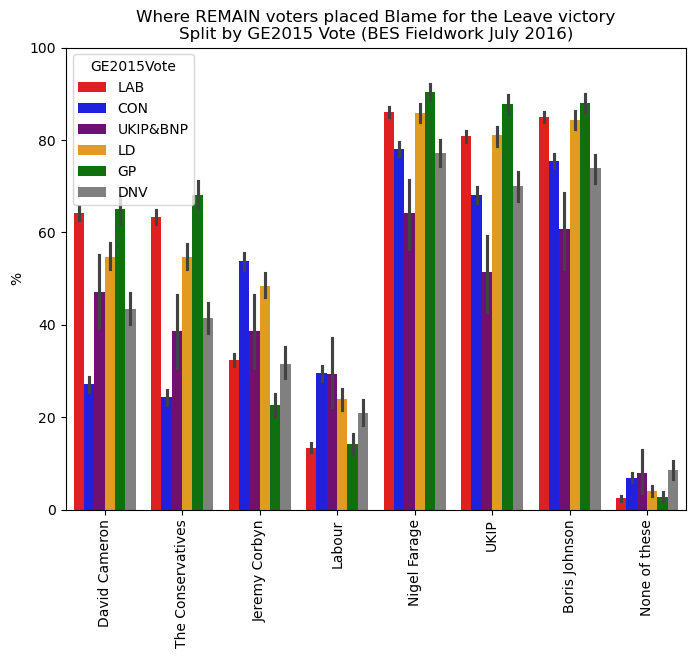

In [111]:
plt.figure(figsize=(8,6))
palette = {"CON":'blue',"LAB":'red',"UKIP&BNP":'purple',"DNV":'grey',"LD":'orange',"GP":'green'}
bar = sns.barplot(data=blameLeave,x="BlameOrCredit",y="value",hue="GE2015Vote",palette=palette );

# # Define some hatches
# hatches = ['-', '+', 'x', '\\', '*', 'o']

# # Loop over the bars
# for i,thisbar in enumerate(bar.patches):
#     # Set a different hatch for each bar
#     thisbar.set_hatch(hatches[i])

plt.xticks(rotation=90);
plt.title("Where REMAIN voters placed Blame for the Leave victory\nSplit by GE2015 Vote (BES Fieldwork July 2016)");
plt.ylabel("%");
plt.xlabel("");
plt.ylim([0,100]);

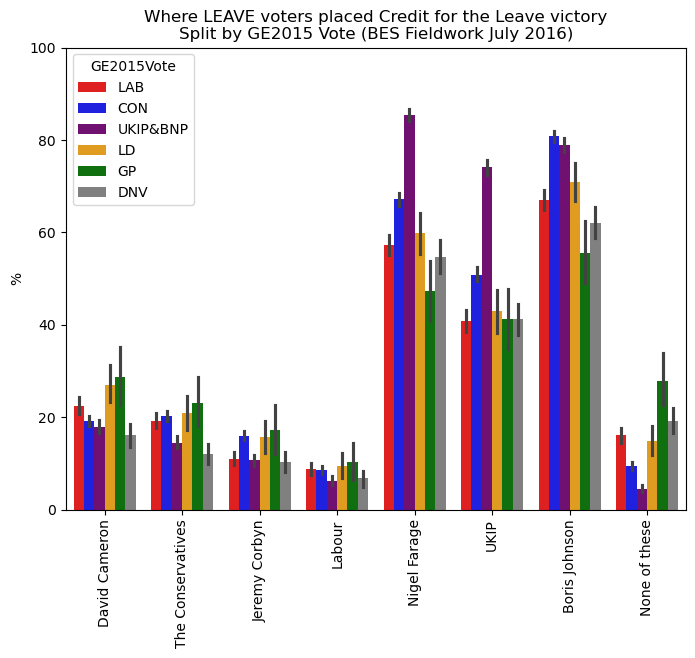

In [112]:
plt.figure(figsize=(8,6))
palette = {"CON":'blue',"LAB":'red',"UKIP&BNP":'purple',"DNV":'grey',"LD":'orange',"GP":'green'}
sns.barplot(data=creditLeave,x="BlameOrCredit",y="value",hue="GE2015Vote",palette=palette);
plt.xticks(rotation=90);
plt.ylabel("%");
plt.xlabel("");
plt.ylim([0,100]);
plt.title("Where LEAVE voters placed Credit for the Leave victory\nSplit by GE2015 Vote (BES Fieldwork July 2016)");

In [10]:
(BES_Panel[search(BES_Panel,"blameLeave").index]=="Yes").sum()

blameLeave_1W9      7471
blameLeave_2W9      7477
blameLeave_3W9      5469
blameLeave_4W9      2944
blameLeave_5W9     11705
blameLeave_6W9     10859
blameLeave_7W9       671
blameLeave_8W9     11536
blameLeave_12W9      575
dtype: int64

In [5]:
BES_Panel["creditLeave_1W9"]

id
1          No
2         Yes
3         NaN
4         NaN
5         NaN
         ... 
120138    NaN
120139    NaN
120140    NaN
120141    NaN
120142    NaN
Name: creditLeave_1W9, Length: 118700, dtype: category
Categories (3, object): ['No' < 'Yes' < 'Don't know']

In [126]:
search(BES_Panel,"euRefVote")

euRefVoteW1                30179
euRefVoteW2                26446
euRefVoteW3                27830
euRefVoteW4                31550
euRefVoteW6                30258
euRefVoteW7                30895
euRefVoteSqueezeW7          4717
euRefVoteUnsqueezeW7       30895
euRefVotePostalW8           4325
euRefVoteW8                33500
euRefVoteSqueezeW8          3818
euRefVoteUnsqueezeW8       29175
euRefVote2W8               29175
euRefVoteHypotheticalW9     1788
euRefVoteW9                28247
euRefVoteW10               30236
euRefVoteW11               30956
euRefVoteW12               34394
euRefVoteW13               31133
euRefVoteW14               31063
euRefVoteW15               30602
euRefVoteW16               37959
euRefVoteW17               34040
euRefVoteW18               37442
euRefVoteW19               32176
euRefVoteAfterW20          30950
euRefVoteAfterW21          29759
euRefVoteAfterW22          27592
euRefVoteAfterW23          30427
euRefVoteAfterW24          15071
euRefVoteA

In [125]:
round(pd.crosstab(BES_Panel["p_eurefvote"].replace("Don't know",np.nan),BES_Panel["generalElectionVoteW29"].replace("Don't know",np.nan),
            values=BES_Panel["wt_new_W29"],aggfunc=sum,normalize='columns')*100,2)

generalElectionVoteW29,Conservative,Labour,Liberal Democrat,Scottish National Party (SNP),Plaid Cymru,Green Party,Other,Brexit Party/Reform UK,An independent candidate
p_eurefvote,,,,,,,,,
I voted to remain,32.72,73.34,72.13,80.59,67.85,75.41,39.26,9.01,57.07
I voted to leave,67.28,26.66,27.87,19.41,32.15,24.59,60.74,90.99,42.93


In [129]:
round(pd.crosstab(BES_Panel["euRefVoteAfterW29"].replace({"Don't know":np.nan,"I would not vote":np.nan}),BES_Panel["generalElectionVoteW29"].replace("Don't know",np.nan),
            values=BES_Panel["wt_new_W29"],aggfunc=sum,normalize='columns')*100,2)

generalElectionVoteW29,Conservative,Labour,Liberal Democrat,Scottish National Party (SNP),Plaid Cymru,Green Party,Other,Brexit Party/Reform UK,An independent candidate
euRefVoteAfterW29,,,,,,,,,
Rejoin the EU,23.35,84.5,82.37,93.6,81.06,87.36,45.83,11.12,64.45
Stay out of the EU,76.65,15.5,17.63,6.4,18.94,12.64,54.17,88.88,35.55


In [130]:
round(pd.crosstab(BES_Panel["p_eurefvote"].replace("Don't know",np.nan),BES_Panel["p_past_vote_2015"].replace("Don't know",np.nan),
            values=BES_Panel["wt_new_W29"],aggfunc=sum,normalize='columns')*100,2)

p_past_vote_2015,Conservative,Labour,Liberal Democrat,Scottish National Party (SNP),Plaid Cymru,United Kingdom Independence Party (UKIP),Green Party,British National Party (BNP),Other
p_eurefvote,,,,,,,,,
I voted to remain,37.75,68.12,70.2,63.68,63.04,5.03,78.09,14.39,41.07
I voted to leave,62.25,31.88,29.8,36.32,36.96,94.97,21.91,85.61,58.93


In [131]:
round(pd.crosstab(BES_Panel["p_eurefvote"].replace("Don't know",np.nan),BES_Panel["p_past_vote_2017"].replace("Don't know",np.nan),
            values=BES_Panel["wt_new_W29"],aggfunc=sum,normalize='columns')*100,2)

p_past_vote_2017,Conservative,Labour,Liberal Democrat,Scottish National Party (SNP),Plaid Cymru,United Kingdom Independence Party (UKIP),Green Party,British National Party (BNP),Other
p_eurefvote,,,,,,,,,
I voted to remain,29.33,70.78,81.8,73.05,53.88,3.35,69.66,0.0,34.85
I voted to leave,70.67,29.22,18.2,26.95,46.12,96.65,30.34,0.0,65.15


In [132]:
round(pd.crosstab(BES_Panel["p_eurefvote"].replace("Don't know",np.nan),BES_Panel["p_past_vote_2019"].replace("Don't know",np.nan),
            values=BES_Panel["wt_new_W29"],aggfunc=sum,normalize='columns')*100,2)

p_past_vote_2019,Conservative,Labour,Liberal Democrat,Scottish National Party (SNP),Plaid Cymru,United Kingdom Independence Party (UKIP),Green Party,Other,Brexit Party/Reform UK,An independent candidate
p_eurefvote,,,,,,,,,,
I voted to remain,23.23,78.96,86.03,77.79,66.09,11.54,69.64,38.4,4.49,42.76
I voted to leave,76.77,21.04,13.97,22.21,33.91,88.46,30.36,61.6,95.51,57.24


In [28]:
#### what is the pop % of REFUK fanciers?
## ptv/like

search(BES_Panel,"wt_full")

wt_full_W3                    27839
wt_full_W1W2W3                21489
wt_full_W4                    31328
wt_full_W1W2W3W4              19003
wt_full_W5                    30725
wt_full_W1W2W3W4W5            17673
wt_full_W4W5                  28096
wt_full_W1W2W3W4W5W6          16807
wt_full_W4W5W6                26144
wt_full_W4W6                  27638
wt_full_W1W2W3W4W5W6W7W8      11411
wt_full_W7W8                  24428
wt_full_W1W2W3W4W5W6W7W8W9    10172
wt_full_W7W8W9                20918
wt_full_W10                   30236
wt_full_W11                   30956
wt_full_W1_W11                 6473
wt_full_W1                    30235
wt_full_W2                    30211
wt_full_W1W2                  26866
wt_full_W1W2W3W4W5W6W7        13313
dtype: int64

In [149]:
search(BES_Panel,"likeLab|likeGrn|likeLD")

likeLabW1     15145
likeLDW1      15145
likeGrnW1     15147
likeLabW2     15369
likeLDW2      15366
              ...  
likeLDW28     31582
likeGrnW28    31582
likeLabW29    31098
likeLDW29     31098
likeGrnW29    31098
Length: 86, dtype: int64

In [182]:
party_set = ["BNP","UKIP","BrexitParty"]
party_set = ["Lab","LD","Grn"]

# party_set = ["Con","BrexitParty"]
# party_set = ["Lab","LD",]
store_df = pd.DataFrame(columns = ["wave","party","type","share"])
store_id = 0 



for wave in range(1,26):

    wt_var = search(BES_Panel,"(wt_new_W"+str(wave)+"|wt_full_W"+str(wave)+")($|_result)").index[0]
    print(wave,wt_var)
    party_present = []

    mask = BES_Panel[wt_var].notnull()
    # mask = BES_Panel["countryW"+str(wave)]=="England"
    print(mask.sum())

    for party in party_set:
        party_like = "like"+party+"W"+str(wave)
        if party_like in BES_Panel.columns:
            party_present.append(party_like)
            ct = pd.crosstab(BES_Panel[party_like][mask],
                             BES_Panel[party_like][mask],
                             values=BES_Panel[wt_var][mask],
                             aggfunc=sum,normalize='all')
            
            dislike = ct[ct.columns[0:5]].sum().sum()
            store_df.loc[store_id] = [ wave, party, "dislike", dislike ]
            store_id = store_id+1
            
            meh = ct["5"].sum()
            store_df.loc[store_id] = [ wave, party, "meh", meh ]
            store_id = store_id+1
            
            like = ct[ct.columns[6:11]].sum().sum()
            store_df.loc[store_id] = [ wave, party, "like", like ]
            store_id = store_id+1
            
            dk = ct["Don't know"].sum()
            store_df.loc[store_id] = [ wave, party, "dk", dk ]
            store_id = store_id+1

    if party_present:
    
        best_like = BES_Panel[party_present][mask].replace("Don't know",np.nan).max(axis=1)
        best_like = best_like.cat.add_categories(["Don't know"])
        best_like.loc[ (BES_Panel[party_present][mask]=="Don't know").all(axis=1)   ] = "Don't know"
        party = "REFUK Best"
        
        ct = pd.crosstab(best_like,
                         best_like,
                         values=BES_Panel[wt_var][mask],
                         aggfunc=sum,normalize='all')
        
        dislike = ct[ct.columns[0:5]].sum().sum()
        store_df.loc[store_id] = [ wave, party, "dislike", dislike ]
        store_id = store_id+1
        
        meh = ct["5"].sum()
        store_df.loc[store_id] = [ wave, party, "meh", meh ]
        store_id = store_id+1
        
        like = ct[ct.columns[6:11]].sum().sum()
        store_df.loc[store_id] = [ wave, party, "like", like ]
        store_id = store_id+1
        
        dk = ct["Don't know"].sum()
        store_df.loc[store_id] = [ wave, party, "dk", dk ]
        store_id = store_id+1                
            
wave_to_date = BES_file_manifest[BES_file_manifest["Only_or_Combined"]=="Only"].set_index("Wave No")["Date_Start"]

wave_to_date.loc[26] = "Apr-24"
wave_to_date.loc[27] = "May-24"
wave_to_date.loc[28] = "Jun-24"
wave_to_date.loc[29] = "Jul-24"

wave_to_date = pd.to_datetime(wave_to_date,format="%b-%y")
store_df["date"] = store_df["wave"].apply(lambda x: wave_to_date.loc[x])

replace_dict = {"dislike":"Strongly dislike-4","meh":"5","like":"6-Strongly like","dk":"Don't know"}
store_df["type"] = store_df["type"].replace(replace_dict)

1 wt_full_W1
30235
2 wt_full_W2
30211
3 wt_full_W3
27839
4 wt_full_W4
31328
5 wt_full_W5
30725
6 wt_new_W6
30073
7 wt_new_W7
30895
8 wt_new_W8
33501
9 wt_new_W9
30035
10 wt_new_W10
30236
11 wt_new_W11
30956
12 wt_new_W12
34394
13 wt_new_W13_result
31135
14 wt_new_W14
31063
15 wt_new_W15
30842
16 wt_new_W16
37959
17 wt_new_W17
34365
18 wt_new_W18
37824
19 wt_new_W19_result
32176
20 wt_new_W20
31468
21 wt_new_W21
30281
22 wt_new_W22
28113
23 wt_new_W23
30949
24 wt_new_W24
15439
25 wt_new_W25
30407


In [183]:
party_present

['likeLabW25', 'likeLDW25', 'likeGrnW25']

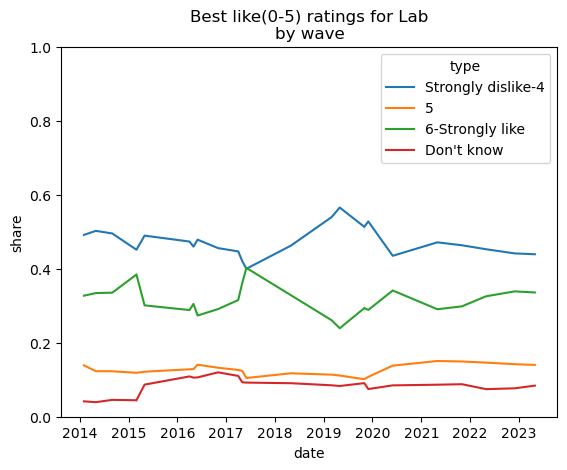

In [184]:
sns.lineplot(data=store_df[store_df["party"]=="Lab"],x="date",y="share",hue="type");
plt.ylim([0,1]);
plt.title("Best like(0-5) ratings for Lab\nby wave");

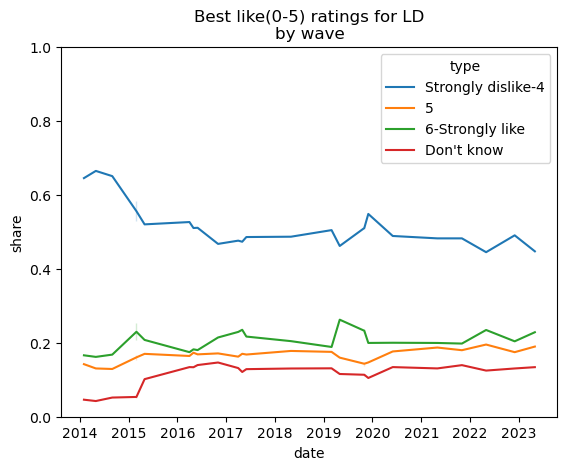

In [185]:
sns.lineplot(data=store_df[store_df["party"]=="LD"],x="date",y="share",hue="type");
plt.ylim([0,1]);
plt.title("Best like(0-5) ratings for LD\nby wave");

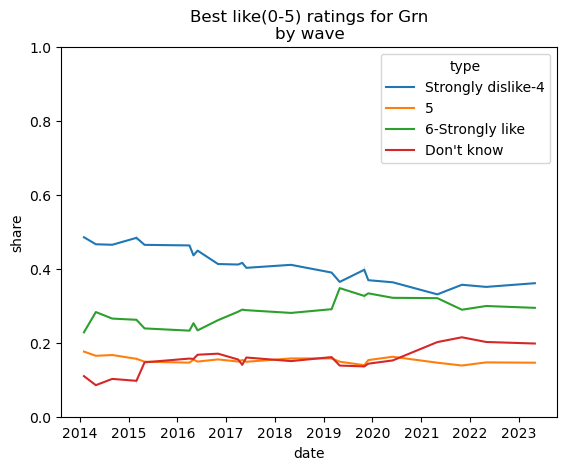

In [186]:
sns.lineplot(data=store_df[store_df["party"]=="Grn"],x="date",y="share",hue="type");
plt.ylim([0,1]);
plt.title("Best like(0-5) ratings for Grn\nby wave");

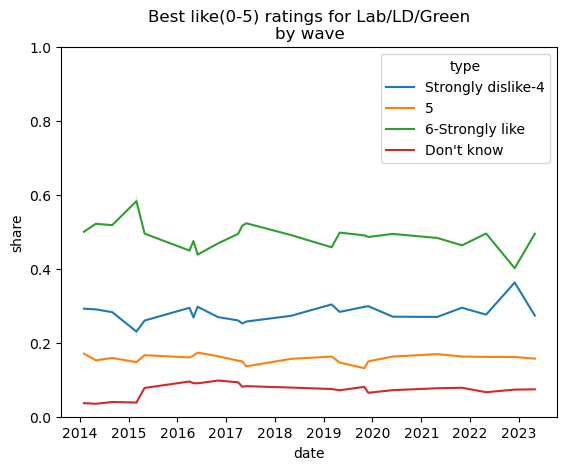

In [188]:
sns.lineplot(data=store_df[store_df["party"]=="REFUK Best"],x="date",y="share",hue="type");
plt.ylim([0,1]);
plt.title("Best like(0-5) ratings for Lab/LD/Green\nby wave");

In [134]:
BES_Panel[search(BES_Panel,"^countryW\d+$").index].stack().value_counts()

England     721525
Scotland    109626
Wales        65254
Name: count, dtype: int64

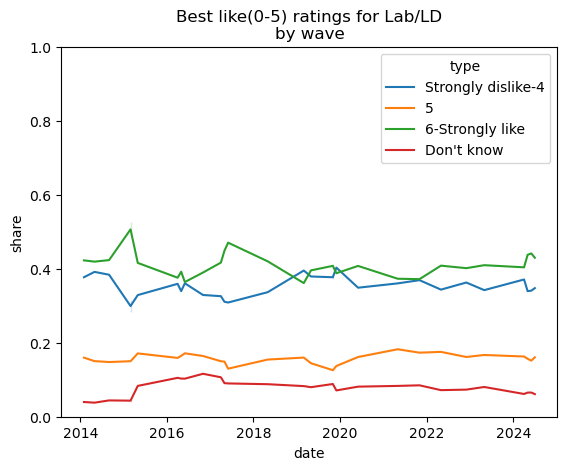

In [158]:
sns.lineplot(data=store_df[store_df["party"]=="REFUK Best"],x="date",y="share",hue="type");
plt.ylim([0,1]);
plt.title("Best like(0-5) ratings for Lab/LD\nby wave");

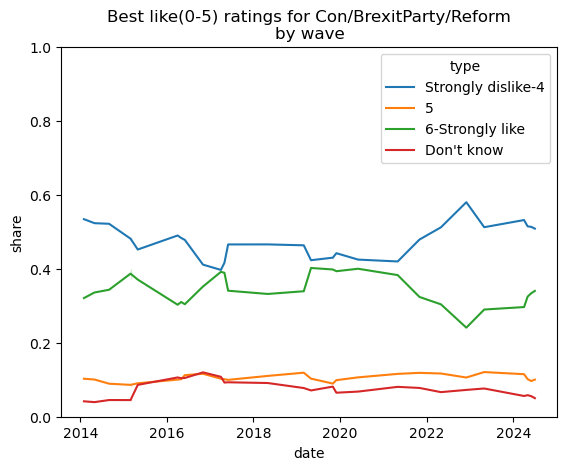

In [156]:
sns.lineplot(data=store_df[store_df["party"]=="REFUK Best"],x="date",y="share",hue="type");
plt.ylim([0,1]);
plt.title("Best like(0-5) ratings for Con/BrexitParty/Reform\nby wave");

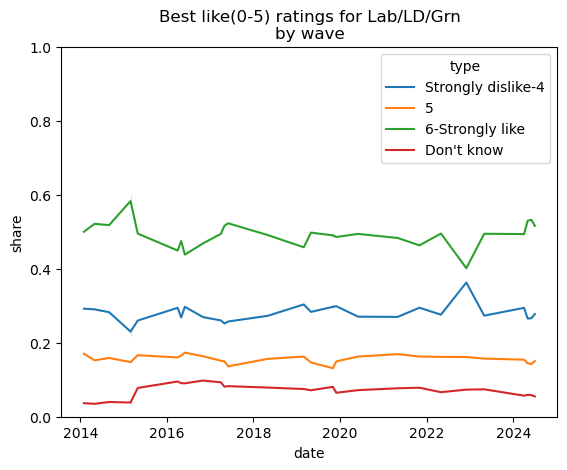

In [151]:
sns.lineplot(data=store_df[store_df["party"]=="REFUK Best"],x="date",y="share",hue="type");
plt.ylim([0,1]);
plt.title("Best like(0-5) ratings for Lab/LD/Grn\nby wave");

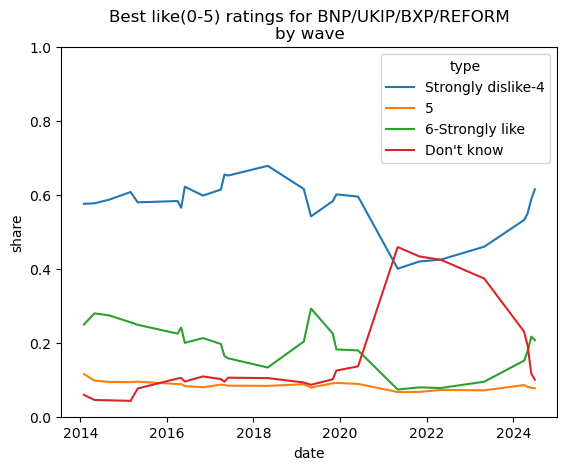

In [146]:
sns.lineplot(data=store_df[store_df["party"]=="REFUK Best"],x="date",y="share",hue="type");
plt.ylim([0,1]);
plt.title("Best like(0-5) ratings for BNP/UKIP/BXP/REFORM\nby wave");

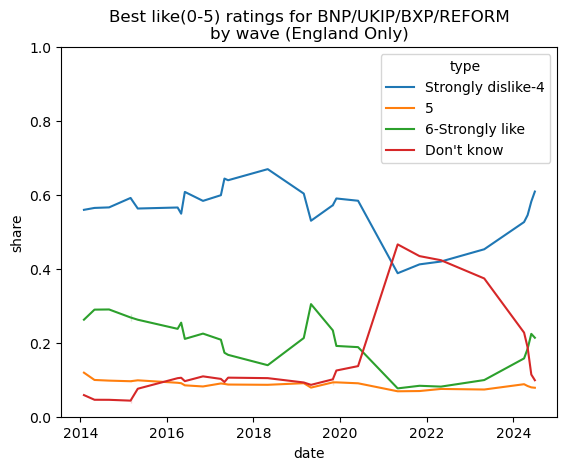

In [144]:
sns.lineplot(data=store_df[store_df["party"]=="REFUK Best"],x="date",y="share",hue="type");
plt.ylim([0,1]);
plt.title("Best like(0-5) ratings for BNP/UKIP/BXP/REFORM\nby wave (England Only)");

<Axes: xlabel='wave', ylabel='share'>

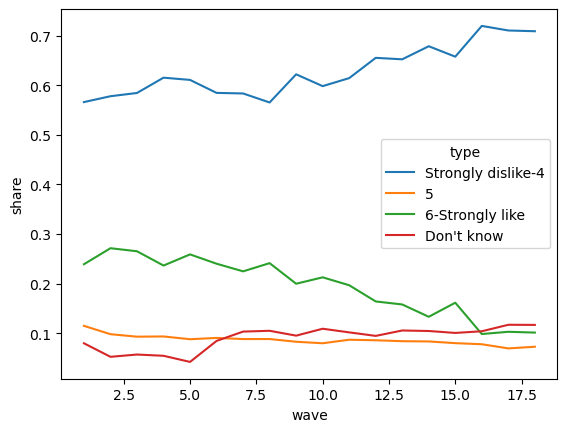

In [127]:
sns.lineplot(data=store_df[store_df["party"]=="UKIP"],x="wave",y="share",hue="type")

<Axes: xlabel='wave', ylabel='share'>

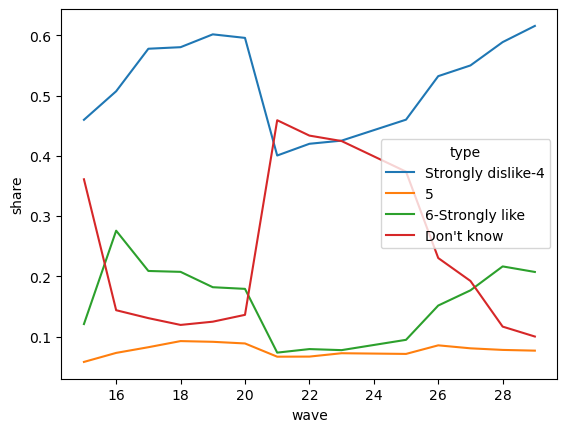

In [128]:
sns.lineplot(data=store_df[store_df["party"]=="BrexitParty"],x="wave",y="share",hue="type")

<Axes: xlabel='wave', ylabel='share'>

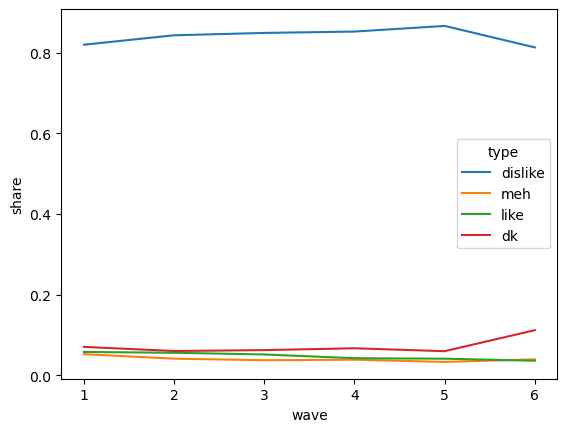

In [94]:
sns.lineplot(data=store_df[store_df["party"]=="BNP"],x="wave",y="share",hue="type")

In [72]:
### England Only
### Compare with LAB/GP/LD

### add dates
### 


likeUKIPW1            15142
likeBNPW1             15133
likeUKIPW2            15362
likeBNPW2             15351
likeUKIPW3            13854
likeBNPW3             13854
likeUKIPW4            15695
likeBNPW4             15695
likeUKIPW5            15443
likeBNPW5             15443
likeUKIPW6            15008
likeBNPW6             15008
likeUKIPW7            30895
likeUKIPW8            33501
likeUKIPW9            30035
likeUKIPW10           30236
likeUKIPW11           30956
likeUKIPW12           34394
likeUKIPW13           31133
likeUKIPW14           31063
likeUKIPW15           30842
likeBrexitPartyW15    30842
likeUKIPW16           37959
likeBrexitPartyW16    37959
likeBrexitPartyW17    34365
likeUKIPW17           34365
likeBrexitPartyW18    37824
likeUKIPW18           37824
likeBrexitPartyW19    32176
likeBrexitPartyW20    31468
likeBrexitPartyW21    30281
likeBrexitPartyW22    28113
likeBrexitPartyW23    30949
likeBrexitPartyW25    30407
likeBrexitPartyW26    30064
likeBrexitPartyW27  

In [164]:
wt_var = "wt_new_W25"
party_like = "likeLabW25"

ct = pd.crosstab(BES_Panel[party_like],
                 BES_Panel[party_like],
                 values=BES_Panel[wt_var],
                 aggfunc=sum,normalize='all')

ct 
like = ct[ct.columns[6:11]].sum().sum()
like

0.33615355126308644

In [163]:
search(BES_Panel,"likeBrexitPartyW16")

likeBrexitPartyW16    37959
dtype: int64

In [171]:
ct

col_0,Strongly dislike,1,2,3,4,5,6,7,8,9,Strongly like,Don't know
row_0,,,,,,,,,,,,
Strongly dislike,0.088956,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
1,0.000000,0.031781,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
2,0.000000,0.000000,0.043125,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
3,0.000000,0.000000,0.000000,0.050144,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
4,0.000000,0.000000,0.000000,0.000000,0.063668,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
5,0.000000,0.000000,0.000000,0.000000,0.000000,0.150875,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
6,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.108491,0.000000,0.000000,0.000000,0.000000,0.000000
7,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.138178,0.000000,0.000000,0.000000,0.000000
8,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.130315,0.000000,0.000000,0.000000


In [174]:
BES_Panel["likeLabW25"].value_counts().sort_index()

likeLabW25
Strongly dislike    5271
1                   1849
2                   2129
3                   2246
4                   2485
5                   4173
6                   2900
7                   3021
8                   2317
9                    951
Strongly like       1371
Don't know          1694
Name: count, dtype: int64

In [175]:
BES_Panel["likeLDW25"].value_counts().sort_index()

likeLDW25
Strongly dislike    4547
1                   1779
2                   2182
3                   2565
4                   2974
5                   5758
6                   3243
7                   2306
8                   1283
9                    454
Strongly like        348
Don't know          2968
Name: count, dtype: int64

In [177]:
BES_Panel["likeGrnW25"].value_counts().sort_index()

likeGrnW25
Strongly dislike    4528
1                   1336
2                   1691
3                   1982
4                   2071
5                   4481
6                   2972
7                   2691
8                   1923
9                    825
Strongly like       1083
Don't know          4824
Name: count, dtype: int64